# Econ 4850 · Economic Analysis with Python
## Lecture 2: Python Essentials
Geoffrey Kam, Washington University in St. Louis · g.kam@wustl.edu · Spring 2025

**What you'll learn**

- Python's basic data types and what "duck typing" means.
- Containers (lists, tuples, dictionaries and sets) and slice notation.
- Control flow: loops, `if` statements and loop-control statements.
- How to write functions, including recursive ones, and a first look at classes.

## Overview

- This lecture covers the essential features of Python.

- They are like the grammar of a language:
    - once you have mastered them, you stop thinking about them,
    - and small mistakes are often inconsequential.

- This material can feel dry, but it cannot be avoided. Fortunately, these ideas are easy to understand in Python.

## Data types

- Python stores data and variables as different types.

- Python is a dynamically typed language: you do not declare a variable's type; Python infers it from the value.

- "If it looks like a duck, swims like a duck, and quacks like a duck, then it probably is a duck."

- In Python, this means that if an object behaves like a particular type (e.g. it supports certain methods or properties), it can be treated as that type, regardless of its actual class.

- Here is an example.

In [1]:
# x is an integer
x = 1
type(x)

int

In [2]:
# x is now a float
x = 1.0
type(x)

float

In [3]:
# x is a boolean, y a float and z an integer, yet they compare as equal
x = True
y = 1.0
z = 1
print(x == y == z)
print(type(x))
print(type(y))
print(type(z))

True
<class 'bool'>
<class 'float'>
<class 'int'>


In [4]:
x = True
y = None
z = False
zz = not True
z == zz

True

### Duck typing

- Duck typing is flexible and makes Python easy to learn.
    - This is one reason Python is called a high-level language.

- However, Python has to guess and match types while the program runs, which slows programs down.

- To improve performance, many packages that speed up code (e.g. Numba and JAX) effectively "turn off" duck typing.
    - So you need to understand types even though you do not see them most of the time.

- Another reason to understand types is that variables of different types use different amounts of memory.

### Boolean values

- A boolean is either `True` or `False`.

- Comparison operators (`<`, `>`, `==`, `!=`, `<=`, `>=`) return booleans.

In [5]:
x = True
y = False
# Arithmetic on booleans: True behaves like 1 and False like 0
print(x * y)
# Comparison operators: <, >, ==, !=, <=, >=
print(1 < 2)

0
True


### Integers, floats, strings and casting

- Integer: whole numbers.

- Float: decimal numbers.

- String: text.

- Casting: converting a value from one type to another.

In [6]:
# an integer
x = 1
print(type(x))
# a float
y = 1.0
print(type(y))
# strings: + joins (concatenates) them
x = '1'
y = '2'
print(x + y)
# casting the strings to integers makes + an addition
print(int(x) + int(y))

<class 'int'>
<class 'float'>
12
3


## Data structures (containers)

- A data structure is a systematic way of organizing and storing data so that it can be accessed and modified efficiently.

- In simpler terms, data structures are "containers" that hold and organize data according to certain rules, making large or complex data easier to work with.

- In economics (and scientific computing more generally), we seldom store data in these containers.
    - Still, you need to know them, because their particular properties can cause unexpected errors.

- Some packages are less flexible and accept only certain data structures.

### Lists

- A list is a mutable, ordered collection of elements.

- Lists are defined with square brackets: `[]`.

- They are useful for storing a sequence of items when you need to add, remove or modify elements.

In [7]:
# create an empty list
x = []
# append a string to the list
x.append('hello')
# append an integer to the list
x.append(1)
# append a float to the list
x.append(1.0)
# change the first element of the list to a float
x[0] = 1.0
print(x)
# check the type of x
type(x)

[1.0, 1, 1.0]


list

#### List methods

- Lists come with many methods for editing them, such as `append()`, `extend()` and `index()`.

- In VS Code, the available methods are listed automatically when you type a list's name followed by a dot (e.g. `x.`).

In [8]:
x = [1, 2, 3]
# index(): position of the first element equal to 1
print(x.index(1))
# extend(): append every element of another list
x.extend([1, 2, 3])
print(x)
# x.index('1') would raise a ValueError: the string '1' is not in the list

0
[1, 2, 3, 1, 2, 3]


#### Slice notation

- This is a good opportunity to introduce slice notation.
- Indexing in Python starts from 0.
- Negative indices count from the end:
    - `[-1]` is the last element.
- You can slice with `[start:stop:step]`.
    - Later you will see that this is very useful, because slicing preserves the number of dimensions of an array, whereas indexing with a single integer drops one.

In [9]:
a = ["a", "b", "c", "d", "e"]
# the first element of the list
print(a[0])
# the second element and everything after it
print(a[1:])
# the last element of the list
print(a[-1])
# the format [start:stop:step]
print(a[1:-2:2])
# the list in reverse order
print(a[::-1])

a
['b', 'c', 'd', 'e']
e
['b']
['e', 'd', 'c', 'b', 'a']


### Tuples

- A tuple is an ordered, immutable sequence of items.

- Tuples are defined with parentheses: `()`.

- Because tuples are immutable, trying to change an element raises a `TypeError`. The error in the next cell is expected.

In [10]:
# create a tuple
x = (1, 1, 2, 3)
# try to change an element of the tuple: this raises a TypeError
x[0] = 1

TypeError: 'tuple' object does not support item assignment

In [11]:
# Tuples have no append() method, but they do have count()
x.count(1)

2

### Dictionaries

- A dictionary is a mutable collection of key–value pairs. (Since Python 3.7, dictionaries remember the order in which keys were inserted.)

- Dictionaries are defined with curly braces: `{}`.

In [12]:
economy = {
    "GDP": 1000,
    "Income": 800,
    "Consumption": 300
}
# add a new key-value pair to the dictionary
economy["Recession"] = False
print(economy)
print(type(economy))

# look up a value by its key
economy["GDP"]

{'GDP': 1000, 'Income': 800, 'Consumption': 300, 'Recession': False}
<class 'dict'>


1000

### Sets

- A set is an unordered, mutable collection of unique elements.
- Sets are defined with curly braces `{}` or the `set()` constructor (an empty `{}` creates a dictionary, so an empty set needs `set()`).

In [13]:
unique_numbers = {1, 2, 3, 3, 4}
# the duplicate 3 is stored only once
print(unique_numbers)
print(type(unique_numbers))

{1, 2, 3, 4}
<class 'set'>


### Summary

- Choose the right data structure:
    - Use lists when you need an ordered, mutable sequence.
    - Use tuples when you need an ordered, immutable sequence (data that should not change).
    - Use dictionaries for key–value lookups and easy updates.
    - Use sets for fast membership checks and for storing unique elements.

- Be mindful of mutability:
    - Mutability makes in-place changes easy, but it can also introduce bugs if not handled carefully.

- Use type conversion cautiously:
    - Converting from one type to another can lose data or raise errors if the values are incompatible (e.g. converting `"ABC"` to `int`).

## Control structures

- Control structures direct the flow of execution in a Python program. They let you build logic, loops and decisions.

- You will use them in essentially every piece of scientific computing.
    - Recall the simulation of the AR(1) process in Lecture 1.

### Loops

- The `for` loop is the basic loop.

- Note that indices in Python start at `0` and end at `n-1` for a list of size `n`.

In [14]:
# a for loop without indexing
x = [1, 2, 3]
y = [2, 4, 6]
for i in x:
    print(i)

1
2
3


In [15]:
# a double for loop without indexing
for i in x:
    for j in y:
        print(i, j)

# the same double loop with itertools
import itertools

for i, j in itertools.product(x, y):
    print(i, j)

1 2
1 4
1 6
2 2
2 4
2 6
3 2
3 4
3 6
1 2
1 4
1 6
2 2
2 4
2 6
3 2
3 4
3 6


Python offers several other ways to loop: indexing with `range()`, pairing lists with `zip()`, counting with `enumerate()`, `while` loops and list comprehensions.

In [16]:
# loop over indices with range
for i in range(len(x)):
    print(x[i] + y[i])

3
6
9


In [17]:
# range(start, stop, step)
for i in range(5, 10, 1):
    print(i)

5
6
7
8
9


In [18]:
# zip pairs up the elements of two lists
for pair in zip(x, y):
    print(pair)

(1, 2)
(2, 4)
(3, 6)


In [19]:
# enumerate returns the index together with the element
for i, j in enumerate(x):
    print(i, j)

0 1
1 2
2 3


In [20]:
# while loop
n = 5
while n > 0:
    n -= 1
    print(n)

4
3
2
1
0


In [21]:
# list comprehension
doubles = [2 * x for x in range(8)]
doubles

[0, 2, 4, 6, 8, 10, 12, 14]

#### Exercise: multiplication versus division

Demonstrate why you should never use division when multiplication is available. The `%%timeit` magic times a cell by running it many times.

In [22]:
%%timeit
x = 1
n = 100
for _ in range(n):
    x *= 0.5

1.23 μs ± 25.9 ns per loop (mean ± std. dev. of 7 runs, 1,000,000 loops each)


In [23]:
%%timeit
x = 1
n = 100
for _ in range(n):
    x /= 2

1.86 μs ± 15.6 ns per loop (mean ± std. dev. of 7 runs, 1,000,000 loops each)


#### Exercise: why use list comprehensions?

Using `%%timeit`, compare the time needed to create a list of the squares of 0 to 1_000_000 - 1 with a standard `for` loop and with a list comprehension.

Note that nowadays the difference is small; I rarely use list comprehensions myself.

In [24]:
%%timeit
squares_loop = []
for i in range(1_000_000):
    squares_loop.append(i ** 2)

38 ms ± 1.13 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


In [25]:
%%timeit
squares_comprehension = [i ** 2 for i in range(1_000_000)]

32.9 ms ± 296 μs per loop (mean ± std. dev. of 7 runs, 10 loops each)


### Conditional statements

- You can put an `if` condition inside a `for` loop.

- First, let's look at the most common `if` condition in economics. This is also a chance to get ahead of ourselves and see how to write a function in Python.

In [26]:
# numpy provides -inf and log
import numpy as np

# CRRA utility function
def crra_utility(consumption, gamma):
    if consumption <= 0:
        return -np.inf
    else:  # equivalently: elif consumption > 0:
        if gamma == 1:
            return np.log(consumption)
        else:  # gamma != 1
            return (consumption**(1 - gamma) - 1) / (1 - gamma)

This function is slow and inefficient because it does not use an important feature of NumPy (vectorized operations), but it works well for demonstration.

### Loop-control statements

There are three loop-control statements you need to know:

1. `break`: exit the loop immediately.

2. `continue`: skip the rest of the current iteration and move to the next one.

3. `pass`: a placeholder that does nothing.

In [27]:
# continue: skip i == 2
for i in range(5):
    if i == 2:
        continue
    print(i)

0
1
3
4


In [28]:
# break: stop the loop at i == 2
for i in range(5):
    if i == 2:
        break
    print(i)

0
1


In [29]:
# pass: an empty block that does nothing
for i in range(5):
    pass

## Functions

- We have already used some functions.

- There are three types of functions:

1. built-in functions,

2. third-party functions,

3. user-defined functions.

### Built-in functions

- We have already used `type()` and `print()`.

- `dir()` lists the attributes and methods of an object.

- This is also a good opportunity to introduce f-strings.

In [30]:
# dir
x = 1
dir(x)

['__abs__',
 '__add__',
 '__and__',
 '__bool__',
 '__ceil__',
 '__class__',
 '__delattr__',
 '__dir__',
 '__divmod__',
 '__doc__',
 '__eq__',
 '__float__',
 '__floor__',
 '__floordiv__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getnewargs__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__index__',
 '__init__',
 '__init_subclass__',
 '__int__',
 '__invert__',
 '__le__',
 '__lshift__',
 '__lt__',
 '__mod__',
 '__mul__',
 '__ne__',
 '__neg__',
 '__new__',
 '__or__',
 '__pos__',
 '__pow__',
 '__radd__',
 '__rand__',
 '__rdivmod__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__rfloordiv__',
 '__rlshift__',
 '__rmod__',
 '__rmul__',
 '__ror__',
 '__round__',
 '__rpow__',
 '__rrshift__',
 '__rshift__',
 '__rsub__',
 '__rtruediv__',
 '__rxor__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__sub__',
 '__subclasshook__',
 '__truediv__',
 '__trunc__',
 '__xor__',
 'as_integer_ratio',
 'bit_count',
 'bit_length',
 'conjugate',
 'denominator',
 'from_bytes',
 'imag',
 'numerator',
 '

In [31]:
# f-strings: format values inside a string
value = 123.456789
print(f"Currency format: ${value:,.3f}")  # Output: Currency format: $123.457

name = "Alice"
print(f"|{name:<20}|")  # Left-aligned in 20 characters: |Alice               |
print(f"|{name:>10}|")  # Right-aligned in 10 characters: |     Alice|
print(f"|{name:^10}|")  # Centered in 10 characters:      |  Alice   |

Currency format: $123.457
|Alice               |
|     Alice|
|  Alice   |


In [32]:
# f-strings can also format dates
from datetime import datetime

today = datetime.now()
print(f"Today's date is {today:%Y-%m-%d}.")
# the same format with the strftime method
today.strftime("%Y-%m-%d")

Today's date is 2026-10-25.


'2026-10-25'

In [33]:
# raw f-string: backslashes are treated as literal characters,
# which makes file paths and regular expressions easier to write
name = "Alice"
print(rf"Path: C:\Users\{name}\Documents")

Path: C:\Users\Alice\Documents


### Third-party functions

Functions from packages such as NumPy are used after importing the package.

In [34]:
import numpy as np
np.log(1)

0.0

### Defining your own functions

- A good programmer never repeats themselves.

- This is why it is important to define functions in Python.

In [35]:
# function syntax
def my_function(x, a):
    return a * x + a

- Variables defined inside a function are called local variables.

- You should never rely on global variables, for two reasons:
    1. Some performance-enhancing packages do not support global variables.
    2. They can slow down your function, because Python has to search for where the variable is defined.

The function below uses `b`, which is not defined inside it, so it depends on a global variable.

In [36]:
def bad_function(x):
    return b * x**2

In [37]:
b = 3
bad_function(2)

12

A better approach is to pass the value as an argument. A keyword argument with a default value saves typing when the value rarely changes.

In [38]:
def good_function(x, b=2):
    return b * x**2

print(good_function(2))

8


Functions can contain more complicated logic. Recall the CRRA utility function defined above, which returns $-\infty$ when consumption is not positive. Instead, we can raise an error that explains what went wrong.

In [39]:
# raise an error for invalid input
def crra_utility(consumption, gamma):
    if consumption <= 0:
        raise ValueError("Consumption must be positive")
    else:  # equivalently: elif consumption > 0:
        if gamma == 1:
            return np.log(consumption)
        else:  # gamma != 1
            return (consumption**(1 - gamma) - 1) / (1 - gamma)

Calling the function with negative consumption now raises a `ValueError`. The error in the next cell is expected.

In [40]:
crra_utility(-1, 1)

ValueError: Consumption must be positive

The input of a function can itself be a function.

In [41]:
def square(x):
    return x**2

def apply_and_add(x, func):
    return func(x) + x

apply_and_add(2, square)

6

- You can define a one-line function with `lambda`.

- I use it most of the time to keep my code clean.

In [42]:
def my_function(x, a):
    return a * x

a = 2
f = lambda x: my_function(x, a=a)
f(3)

6

- You can also specify the types of a function's inputs and output (type hints).

- Type hints can make code cleaner and more readable, which is very important.

- However, I do not recommend them, because some packages handle types automatically.

- They are shown here only for completeness.

In [43]:
def multiply(a: int, b: int) -> int:
    return a * b

type(multiply(2, 3))

int

### Recursive function calls

- Sometimes we apply the same operation to a variable many times, starting from an initial condition.

- Sometimes the operation is applied to a function rather than a variable.
    - We will do this at the end of the course.

- Such computations are simple to write in a (backward) recursive way.

- Consider the factorial.

In [44]:
# a recursive factorial function
def factorial(n):
    if n == 0:
        return 1
    else:
        return n * factorial(n - 1)

In [45]:
factorial(5)

120

**Exercise.** Write a recursive function for the Fibonacci sequence:

$$x_t=x_{t-1}+x_{t-2},\quad x_1=1,\quad x_0=0.$$

In [46]:
def fibonacci(n):
    if n <= 1:
        return n
    else:
        return fibonacci(n - 1) + fibonacci(n - 2)

In [47]:
# the first ten Fibonacci numbers
print([fibonacci(i) for i in range(10)])

[0, 1, 1, 2, 3, 5, 8, 13, 21, 34]


## Classes

- I seldom use `class`, for many reasons.

- Classes exist in Python because Python is an [object-oriented programming language](https://python-programming.quantecon.org/oop_intro.html).

- They are common in many machine-learning applications.

- For completeness, the syntax is introduced briefly here. The code in this section comes from [QuantEcon](https://python-programming.quantecon.org/python_oop.html).

In [48]:
class Consumer:

    def __init__(self, w):
        "Initialize consumer with w dollars of wealth"
        self.wealth = w

    def earn(self, y):
        "The consumer earns y dollars"
        self.wealth += y

    def spend(self, x):
        "The consumer spends x dollars if feasible"
        new_wealth = self.wealth - x
        if new_wealth < 0:
            print("Insufficient funds")
        else:
            self.wealth = new_wealth

In [49]:
c1 = Consumer(100)
c1.earn(10)
c1.spend(100)
c1.wealth

10

An example of chaotic dynamics in a nonlinear system (the logistic map):

$$x_{t+1}=rx_t(1-x_t),\quad x_0\in[0,1],\quad r\in[0,4]$$

In [50]:
class Chaos:
    """
    Models the dynamical system :math:`x_{t+1} = r x_t (1 - x_t)`
    """
    def __init__(self, x0, r):
        """
        Initialize with state x0 and parameter r
        """
        self.x, self.r = x0, r

    def update(self):
        "Apply the map to update state."
        self.x = self.r * self.x * (1 - self.x)

    def generate_sequence(self, n):
        "Generate and return a sequence of length n."
        path = []
        for i in range(n):
            path.append(self.x)
            self.update()
        return path

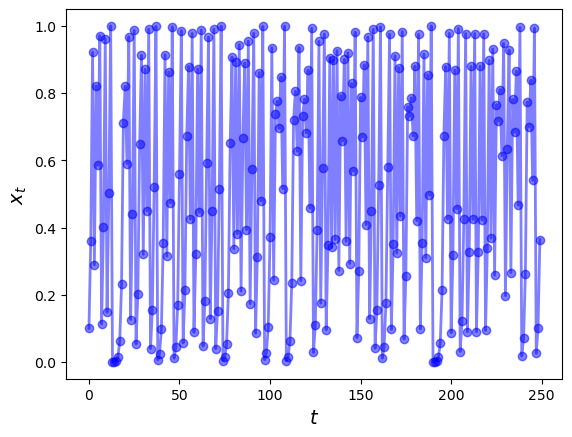

In [51]:
import matplotlib.pyplot as plt

ch = Chaos(0.1, 4.0)
ts_length = 250

fig, ax = plt.subplots()
ax.set_xlabel('$t$', fontsize=14)
ax.set_ylabel('$x_t$', fontsize=14)
x = ch.generate_sequence(ts_length)
ax.plot(range(ts_length), x, 'bo-', alpha=0.5, lw=2, label='$x_t$')
plt.show()

Repeating the simulation for a grid of values of $r$ and plotting the long-run values of $x_t$ gives the bifurcation diagram of the logistic map.

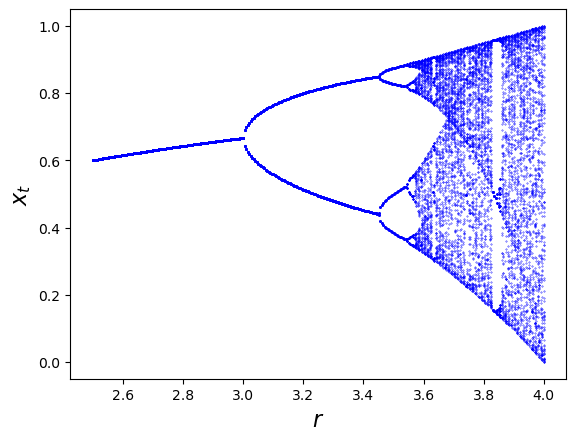

In [52]:
fig, ax = plt.subplots()
ch = Chaos(0.1, 4)
r = 2.5
seq_start = 900
step = 0.005

while r < 4:
    ch.r = r
    tail = ch.generate_sequence(1000)[seq_start:]
    ax.plot([r] * len(tail), tail, 'b.', ms=0.6)
    r = r + step

ax.set_xlabel('$r$', fontsize=16)
ax.set_ylabel('$x_t$', fontsize=16)
plt.show()

## Reminder: be a good programmer

- There are some principles you should always follow:

    1. Don't use magic numbers.

    2. Don't repeat yourself.

    3. Minimize global variables.

    4. Use functions or classes.

- Read [QuantEcon](https://python-programming.quantecon.org/writing_good_code.html) for the details.

The function below runs, but only because the global variable `b = 3` defined earlier is still in memory. Deleting the global `a` has no effect, because `f` uses its own local `a`. A hidden dependence on a global such as `b` is exactly what the principles above warn against.

In [53]:
def f(x):
    a = 2
    return a + b * x

a = 10
del a

f(10)

32

## Summary

- You should know that Python has different types of data.

- You should know that there are different ways to store data collectively, e.g. in a list.

- You should be able to write loops and `if` statements.

- You should be able to write a function.

- You should be able to write a class.